<h2 >Instalacion de librerias</h2>

In [ ]:
!pip install wget
!pip install pandas
!pip install numpy
!pip install matplotlib
!pip install scipy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import wget
import os

In [3]:
url = "https://raw.githubusercontent.com/Acaide04/Analisis_ENFR_2018/refs/heads/ENFR2018/ENFR%202018%20-%20Base%20usuario.txt"


df = pd.read_csv(url, sep="|")
df_original = df


df = df.drop_duplicates()
df = df.replace([98, 99, 999, 9999], pd.NA)
df = df.replace(r'^\s*$', pd.NA, regex=True) 
df = df.drop(columns=[col for col in df.columns if col.endswith("99")])


columnas_ha = [
    col for col in df.columns
    if "biha" in col or col in ["control_hipertension","prevalencia_hipertension"]
]

columnas_al = [
    col for col in df.columns
    if "bial" in col or col in ["promedio_fv_diario", "consumo_fv", "barreras_fyv", "tipo_dieta_razones"]
]

columnas_co = [
    col for col in df.columns
    if "bico" in col or col in ["control_colesterol", "prevalencia_colesterol"]
]

df_HA = df[columnas_ha].copy()
df_AL = df[columnas_al].copy()
df_CO = df[columnas_co].copy()

df_HIPOTESIS = df[['bial03', 'bial04', 'bial05', 'bial06', 'nivel_actividad_fisica', 'imc_bima','promedio_sistolica', 'bima13', 'bhch04', 'bimq05']].copy()


In [4]:
for columna in df_HA:
        print(f"\n--- {columna} ---")
        print("Tipo:", df_HA[columna].dtype)
        print("Nulos:", df_HA[columna].isna().sum())
        print("Valores:", df_HA[columna].value_counts())
        print("NoNulos", df_HA[columna].notna().sum())

df_HA.describe()


df_HA = df_HA.dropna(how="all")


--- biha01 ---
Tipo: object
Nulos: 83
Valores: biha01
1    27142
2     1999
Name: count, dtype: int64
NoNulos 29141

--- biha02 ---
Tipo: object
Nulos: 2275
Valores: biha02
1.0    21561
2.0     3242
3.0     2146
Name: count, dtype: int64
NoNulos 26949

--- biha03 ---
Tipo: object
Nulos: 212
Valores: biha03
3    18579
2     6755
1     3678
Name: count, dtype: int64
NoNulos 29012

--- biha04 ---
Tipo: float64
Nulos: 18791
Valores: biha04
1.0    5713
2.0    4720
Name: count, dtype: int64
NoNulos 10433

--- biha05_01 ---
Tipo: float64
Nulos: 23511
Valores: biha05_01
1.0    2934
2.0    2779
Name: count, dtype: int64
NoNulos 5713

--- biha05_02 ---
Tipo: float64
Nulos: 23511
Valores: biha05_02
1.0    5238
2.0     475
Name: count, dtype: int64
NoNulos 5713

--- biha06 ---
Tipo: float64
Nulos: 24009
Valores: biha06
1.0     3172
2.0     1576
3.0      256
4.0      169
5.0       18
6.0       12
8.0        5
10.0       4
7.0        2
13.0       1
Name: count, dtype: int64
NoNulos 5215

--- biha07

In [5]:
for columna in df_AL:
        print(f"\n--- {columna} ---")
        print("Tipo:", df_AL[columna].dtype)
        print("Nulos:", df_AL[columna].isna().sum())
        print("Valores:", df_AL[columna].value_counts())
        print("NoNulos", df_AL[columna].notna().sum())

df_AL.describe()


df_AL = df_AL.dropna(how="all")


--- bial01 ---
Tipo: object
Nulos: 98
Valores: bial01
1    20780
2     8346
Name: count, dtype: int64
NoNulos 29126

--- bial02 ---
Tipo: int64
Nulos: 0
Valores: bial02
3    18583
2     6825
1     3816
Name: count, dtype: int64
NoNulos 29224

--- bial03 ---
Tipo: float64
Nulos: 571
Valores: bial03
7.0    9549
3.0    4262
2.0    3969
1.0    2916
0.0    2568
5.0    2506
4.0    1953
6.0     930
Name: count, dtype: int64
NoNulos 28653

--- bial04 ---
Tipo: float64
Nulos: 3018
Valores: bial04
1.0     14532
2.0      7582
3.0      2396
4.0       778
5.0       365
7.0       177
6.0       158
10.0       47
1.5        39
8.0        33
0.5        31
2.5        20
12.0       14
9.0        11
15.0        8
13.0        4
1.2         4
4.5         2
14.0        2
11.0        1
17.0        1
2.2         1
Name: count, dtype: int64
NoNulos 26206

--- bial05 ---
Tipo: float64
Nulos: 287
Valores: bial05
7.0    10176
3.0     4788
5.0     3719
2.0     3238
4.0     3019
1.0     1582
6.0     1510
0.0      9

In [6]:
for columna in df_CO:
        print(f"\n--- {columna} ---")
        print("Tipo:", df_CO[columna].dtype)
        print("Nulos:", df_CO[columna].isna().sum())
        print("Valores:", df_CO[columna].value_counts())
        print("NoNulos", df_CO[columna].notna().sum())

df_CO.describe()


df_CO = df_CO.dropna(how="all")


--- bico01 ---
Tipo: object
Nulos: 376
Valores: bico01
1    20576
2     8272
Name: count, dtype: int64
NoNulos 28848

--- bico02 ---
Tipo: object
Nulos: 8812
Valores: bico02
1.0    14568
2.0     3649
3.0     2195
Name: count, dtype: int64
NoNulos 20412

--- bico03 ---
Tipo: object
Nulos: 419
Valores: bico03
2    22422
1     6383
Name: count, dtype: int64
NoNulos 28805

--- bico04 ---
Tipo: float64
Nulos: 22841
Valores: bico04
2.0    3373
1.0    3010
Name: count, dtype: int64
NoNulos 6383

--- bico05_01 ---
Tipo: float64
Nulos: 26214
Valores: bico05_01
1.0    1976
2.0    1034
Name: count, dtype: int64
NoNulos 3010

--- bico05_02 ---
Tipo: float64
Nulos: 26214
Valores: bico05_02
1.0    2182
2.0     828
Name: count, dtype: int64
NoNulos 3010

--- control_colesterol ---
Tipo: object
Nulos: 12413
Valores: control_colesterol
1.0    13830
2.0     2981
Name: count, dtype: int64
NoNulos 16811

--- prevalencia_colesterol ---
Tipo: object
Nulos: 8785
Valores: prevalencia_colesterol
2.0    14150


In [7]:
for columna in df_HIPOTESIS:
        print(f"\n--- {columna} ---")
        print("Tipo:", df_HIPOTESIS[columna].dtype)
        print("Nulos:", df_HIPOTESIS[columna].isna().sum())
        print("Valores:", df_HIPOTESIS[columna].value_counts())
        print("NoNulos", df_HIPOTESIS[columna].notna().sum())

df_HIPOTESIS.describe()


df_HIPOTESIS = df_HIPOTESIS.dropna(how="all")


--- bial03 ---
Tipo: float64
Nulos: 571
Valores: bial03
7.0    9549
3.0    4262
2.0    3969
1.0    2916
0.0    2568
5.0    2506
4.0    1953
6.0     930
Name: count, dtype: int64
NoNulos 28653

--- bial04 ---
Tipo: float64
Nulos: 3018
Valores: bial04
1.0     14532
2.0      7582
3.0      2396
4.0       778
5.0       365
7.0       177
6.0       158
10.0       47
1.5        39
8.0        33
0.5        31
2.5        20
12.0       14
9.0        11
15.0        8
13.0        4
1.2         4
4.5         2
14.0        2
11.0        1
17.0        1
2.2         1
Name: count, dtype: int64
NoNulos 26206

--- bial05 ---
Tipo: float64
Nulos: 287
Valores: bial05
7.0    10176
3.0     4788
5.0     3719
2.0     3238
4.0     3019
1.0     1582
6.0     1510
0.0      905
Name: count, dtype: int64
NoNulos 28937

--- bial06 ---
Tipo: float64
Nulos: 1164
Valores: bial06
1.00     18354
2.00      6616
3.00       990
0.50       768
4.00       400
1.50       334
5.00       204
7.00       172
6.00        94
2.50   

<h2>Hipótesis</h2>

Valores de biha07 (incluye nulos):
biha07
NaN    23961
2.0     3850
1.0     1388
Name: count, dtype: int64

Tabla cruzada tratamiento con medicamentos (biha05_02) vs olvido (biha07)
(0 = no corresponde la pregunta)
biha07       0.0   1.0   2.0
biha05_02                   
0.0        23486     0     0
1.0            0  1388  3850
2.0          475     0     0

Hipertensos medicados: 5238
Nulos en biha07: 0

Tabla de frecuencias:
        Frecuencia  Porcentaje
olvida                        
No            3850        73.5
Sí            1388        26.5


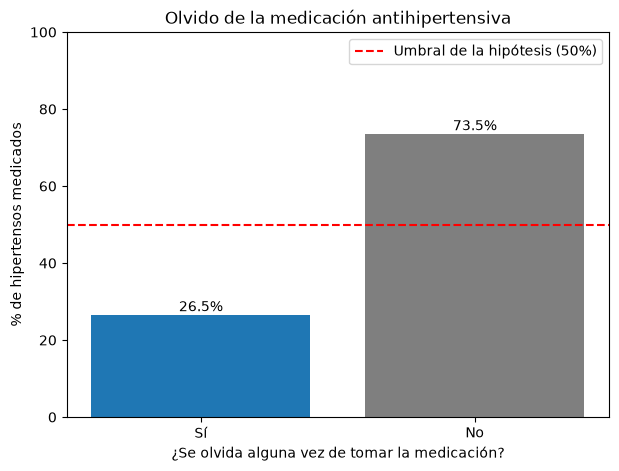


Supuesto de aproximación normal: n·p0 = 2619.0 | n·(1-p0) = 2619.0

[Test z] p̂ = 0.2650 | z = -34.02 | p-valor = 1.0000
No se rechaza H0: no hay evidencia de que más de la mitad se olvide

[Binomial exacto] p-valor = 1.0000
No se rechaza H0

IC 95%: [25.32%, 27.71%]


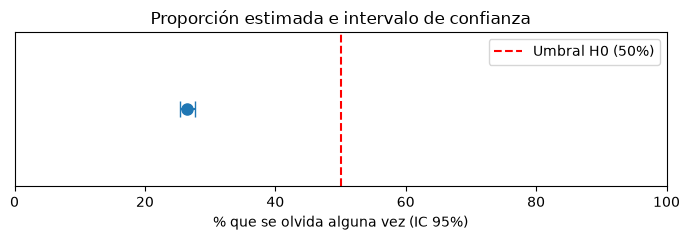


Análisis de sensibilidad:
                                    n       %  IC inf  IC sup  p-valor
Indicador                                                             
Se olvida (biha07)               5238  26.499  25.321  27.711      1.0
Deja si se siente bien (biha08)  5229  11.589  10.750  12.485      1.0
Deja si se siente mal (biha09)   5224   5.188   4.618   5.823      1.0
No adherente (Morisky-Green)     5225  31.943  30.692  33.220      1.0


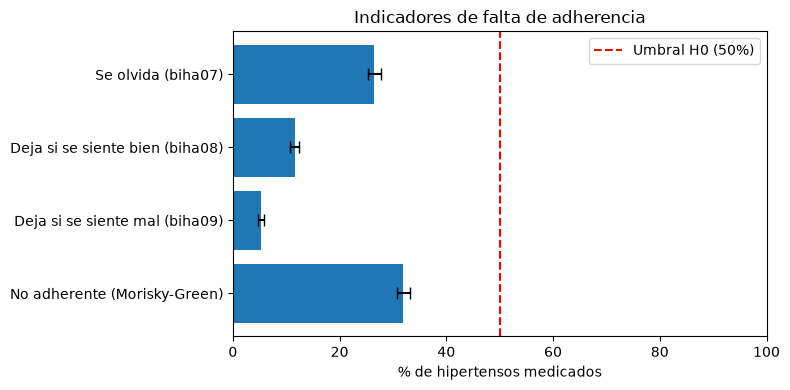

In [9]:
# ============================================================
# HIPÓTESIS UNIVARIADA
# "Más de la mitad de los hipertensos que toman medicación
#  se olvida alguna vez de tomarla"
# H0: p <= 0.5   |   H1: p > 0.5   |   alpha = 0.05
#HAY QUE HACER LO QUE HICIERON LOS CHICOS DE SEPARAR TODO BIEN BONITO Y FACHERO
# ============================================================

# Paso 1: exploración y salto del cuestionario
print("Valores de biha07 (incluye nulos):")
print(df_HA['biha07'].value_counts(dropna=False))
print("\nTabla cruzada tratamiento con medicamentos (biha05_02) vs olvido (biha07)")
print("(0 = no corresponde la pregunta)")
print(pd.crosstab(df_HA['biha05_02'].fillna(0), df_HA['biha07'].fillna(0)))

# Paso 2: población de estudio (hipertensos medicados)
med = df_HA[df_HA['biha05_02'] == 1].copy()
for col in ['biha07', 'biha08', 'biha09']:
    med[col] = pd.to_numeric(med[col], errors='coerce')

print("\nHipertensos medicados:", len(med))
print("Nulos en biha07:", med['biha07'].isna().sum())
med['olvida'] = med['biha07'].map({1: 'Sí', 2: 'No'})

# Paso 3: tabla de frecuencias
frec = pd.DataFrame({
    'Frecuencia': med['olvida'].value_counts(),
    'Porcentaje': med['olvida'].value_counts(normalize=True) * 100
})
print("\nTabla de frecuencias:")
print(frec.round(2))

# Paso 4: gráfico de barras contra el umbral de la hipótesis
porcentajes = med['olvida'].value_counts(normalize=True)[['Sí', 'No']] * 100

plt.figure(figsize=(7, 5))
plt.bar(porcentajes.index, porcentajes.values, color=['tab:blue', 'tab:gray'])
plt.axhline(50, color='red', linestyle='--', label='Umbral de la hipótesis (50%)')
for i, v in enumerate(porcentajes.values):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.ylim(0, 100)
plt.xlabel('¿Se olvida alguna vez de tomar la medicación?')
plt.ylabel('% de hipertensos medicados')
plt.title('Olvido de la medicación antihipertensiva')
plt.legend()
plt.show()

# Paso 5: datos para los tests y verificación de supuestos
n = len(med)
x = int((med['olvida'] == 'Sí').sum())
p_hat = x / n
p0 = 0.5
alpha = 0.05
print("\nSupuesto de aproximación normal: n·p0 =", n * p0, "| n·(1-p0) =", n * (1 - p0))

# Paso 6a: test z para una proporción (test principal)
z = (p_hat - p0) / np.sqrt(p0 * (1 - p0) / n)
p_valor = stats.norm.sf(z)   # cola derecha: H1 es p > 0.5
print("\n[Test z] p̂ = %.4f | z = %.2f | p-valor = %.4f" % (p_hat, z, p_valor))
if p_valor < alpha:
    print("Se rechaza H0: más de la mitad se olvida")
else:
    print("No se rechaza H0: no hay evidencia de que más de la mitad se olvide")

# Paso 6b: test binomial exacto
res = stats.binomtest(x, n, p=p0, alternative='greater')
print("\n[Binomial exacto] p-valor = %.4f" % res.pvalue)
print("Se rechaza H0" if res.pvalue < alpha else "No se rechaza H0")


# Paso 7: intervalo de confianza del 95% (Wilson)
ic = stats.binomtest(x, n).proportion_ci(confidence_level=0.95, method='wilson')
print("\nIC 95%%: [%.2f%%, %.2f%%]" % (ic.low * 100, ic.high * 100))

plt.figure(figsize=(7, 2.5))
plt.errorbar(p_hat * 100, 0, xerr=[[(p_hat - ic.low) * 100], [(ic.high - p_hat) * 100]],
             fmt='o', capsize=6, markersize=8)
plt.axvline(50, color='red', linestyle='--', label='Umbral H0 (50%)')
plt.xlim(0, 100)
plt.yticks([])
plt.xlabel('% que se olvida alguna vez (IC 95%)')
plt.title('Proporción estimada e intervalo de confianza')
plt.legend()
plt.tight_layout()
plt.show()

# Paso 8: análisis de sensibilidad (indicador de Morisky-Green)
items = med[['biha07', 'biha08', 'biha09']]
med['no_adherente'] = np.where((items == 1).any(axis=1), 1,
                       np.where(items.notna().all(axis=1), 0, np.nan))

indicadores = {
    'Se olvida (biha07)': med['biha07'].map({1: 1, 2: 0}),
    'Deja si se siente bien (biha08)': med['biha08'].map({1: 1, 2: 0}),
    'Deja si se siente mal (biha09)': med['biha09'].map({1: 1, 2: 0}),
    'No adherente (Morisky-Green)': med['no_adherente'],
}
filas = []
for nombre, serie in indicadores.items():
    s = serie.dropna()
    k = int(s.sum())
    r = stats.binomtest(k, len(s), p=p0, alternative='greater')
    ic_i = stats.binomtest(k, len(s)).proportion_ci(method='wilson')
    filas.append({'Indicador': nombre, 'n': len(s), '%': 100 * k / len(s),
                  'IC inf': 100 * ic_i.low, 'IC sup': 100 * ic_i.high, 'p-valor': r.pvalue})
sens = pd.DataFrame(filas).set_index('Indicador')
print("\nAnálisis de sensibilidad:")
print(sens.round(3))

plt.figure(figsize=(8, 4))
plt.barh(sens.index, sens['%'], color='tab:blue',
         xerr=[sens['%'] - sens['IC inf'], sens['IC sup'] - sens['%']], capsize=4)
plt.gca().invert_yaxis()
plt.axvline(50, color='red', linestyle='--', label='Umbral H0 (50%)')
plt.xlim(0, 100)
plt.xlabel('% de hipertensos medicados')
plt.title('Indicadores de falta de adherencia')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# HIPÓTESIS BIVARIADA
# "Quienes agregan sal con más frecuencia a la comida cocida
#  tienen mayor prevalencia de hipertensión"
# H0: la prevalencia de hipertensión es independiente de la frecuencia de uso de sal
# H1: existe asociación entre ambas   |   alpha = 0.05
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Paso 1: exploración de las variables
print("bial02 (1 = siempre/casi siempre, 2 = raras veces, 3 = nunca):")
print(df['bial02'].value_counts(dropna=False))
print("\nprevalencia_hipertension (1 = Sí, 2 = No):")
print(df['prevalencia_hipertension'].value_counts(dropna=False))

# Paso 2: armado del dataframe de la hipótesis
biv = df[['bial02', 'prevalencia_hipertension', 'rango_edad']].apply(pd.to_numeric, errors='coerce').dropna()
orden_sal = ['Siempre/casi siempre', 'Raras veces', 'Nunca']
biv['sal'] = pd.Categorical(biv['bial02'].map({1: 'Siempre/casi siempre', 2: 'Raras veces', 3: 'Nunca'}),
                            categories=orden_sal, ordered=True)
biv['hta'] = biv['prevalencia_hipertension'].map({1: 'Sí', 2: 'No'})
print("\nCasos válidos:", len(biv))

# Paso 3: tabla de contingencia (absoluta y % por fila)
tabla = pd.crosstab(biv['sal'], biv['hta'])[['Sí', 'No']]
print("\nTabla de contingencia (frecuencias absolutas):")
print(tabla)
print("\nPrevalencia de hipertensión por categoría (% por fila):")
print((pd.crosstab(biv['sal'], biv['hta'], normalize='index')[['Sí', 'No']] * 100).round(1))

# Paso 4: gráfico de prevalencia por categoría con IC 95%
prev, ic_inf, ic_sup = [], [], []
for cat in orden_sal:
    k = int(tabla.loc[cat, 'Sí'])
    m = int(tabla.loc[cat].sum())
    ic = stats.binomtest(k, m).proportion_ci(method='wilson')
    prev.append(100 * k / m)
    ic_inf.append(100 * ic.low)
    ic_sup.append(100 * ic.high)
prev, ic_inf, ic_sup = np.array(prev), np.array(ic_inf), np.array(ic_sup)

plt.figure(figsize=(7, 5))
plt.bar(orden_sal, prev, color='tab:blue', yerr=[prev - ic_inf, ic_sup - prev], capsize=6)
for i, v in enumerate(prev):
    plt.text(i, ic_sup[i] + 1, f'{v:.1f}%', ha='center')
plt.ylim(0, 60)
plt.xlabel('¿Agrega sal a la comida ya cocida?')
plt.ylabel('Prevalencia de hipertensión (%)')
plt.title('Prevalencia de hipertensión según uso de sal (IC 95%)')
plt.show()

# Paso 5: chi-cuadrado de independencia
chi2, p_valor, gl, esperadas = stats.chi2_contingency(tabla)
print("\nFrecuencias esperadas bajo H0:")
print(pd.DataFrame(esperadas, index=tabla.index, columns=tabla.columns).round(1))
print("Mínima frecuencia esperada:", round(esperadas.min(), 1), "(supuesto: todas >= 5)")

print("\n[Chi-cuadrado] χ² = %.2f | gl = %d | p-valor = %.4g" % (chi2, gl, p_valor))
if p_valor < 0.05:
    print("Se rechaza H0: existe asociación entre uso de sal e hipertensión")
else:
    print("No se rechaza H0: no hay evidencia de asociación")

# Paso 6: V de Cramér (fuerza de la asociación)
n = tabla.values.sum()
v_cramer = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
print("\nV de Cramér = %.3f" % v_cramer)
print("Interpretación: < 0.1 muy débil | 0.1-0.3 débil | 0.3-0.5 moderada | > 0.5 fuerte")

# Paso 7: residuos estandarizados ajustados (dirección de la asociación)
fila = tabla.sum(axis=1).values[:, None] / n
col = tabla.sum(axis=0).values[None, :] / n
residuos = (tabla.values - esperadas) / np.sqrt(esperadas * (1 - fila) * (1 - col))
residuos = pd.DataFrame(residuos, index=tabla.index, columns=tabla.columns)
print("\nResiduos estandarizados ajustados (|r| > 1.96 = celda significativa):")
print(residuos.round(2))

plt.figure(figsize=(7, 4))
plt.imshow(residuos.values, cmap='coolwarm', vmin=-10, vmax=10)
plt.colorbar(label='Residuo ajustado')
plt.xticks([0, 1], ['HTA: Sí', 'HTA: No'])
plt.yticks(range(3), orden_sal)
for i in range(3):
    for j in range(2):
        plt.text(j, i, f'{residuos.values[i, j]:.1f}', ha='center', va='center')
plt.title('Residuos ajustados del chi-cuadrado')
plt.tight_layout()
plt.show()

# Paso 8: test z para dos proporciones (dirección planteada en la hipótesis)
# H0: p_siempre <= p_nunca   |   H1: p_siempre > p_nunca
k1, n1 = tabla.loc['Siempre/casi siempre', 'Sí'], tabla.loc['Siempre/casi siempre'].sum()
k2, n2 = tabla.loc['Nunca', 'Sí'], tabla.loc['Nunca'].sum()
p1, p2 = k1 / n1, k2 / n2
p_pool = (k1 + k2) / (n1 + n2)
z = (p1 - p2) / np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
p_valor_z = stats.norm.sf(z)
print("\n[Test z dos proporciones] Siempre: %.1f%% | Nunca: %.1f%%" % (100 * p1, 100 * p2))
print("z = %.2f | p-valor (H1: siempre > nunca) = %.4f" % (z, p_valor_z))
if p_valor_z < 0.05:
    print("Se rechaza H0: quienes agregan sal siempre tienen mayor prevalencia")
else:
    print("No se rechaza H0: quienes agregan sal siempre NO tienen mayor prevalencia")

# Paso 9: control por edad (posible variable de confusión)
etq_edad = {1: '18-24', 2: '25-34', 3: '35-49', 4: '50-64', 5: '65+'}
print("\n% que agrega sal siempre/casi siempre por grupo de edad:")
print((pd.crosstab(biv['rango_edad'].map(etq_edad), biv['sal'], normalize='index') * 100).round(1))

prev_edad = pd.crosstab([biv['rango_edad'].map(etq_edad), biv['sal']], biv['hta'],
                        normalize='index')['Sí'].unstack() * 100
print("\nPrevalencia de hipertensión (%) por edad y uso de sal:")
print(prev_edad.round(1))

plt.figure(figsize=(8, 5))
for cat, marcador in zip(orden_sal, ['o', 's', '^']):
    plt.plot(prev_edad.index, prev_edad[cat], marker=marcador, label=cat)
plt.xlabel('Grupo de edad')
plt.ylabel('Prevalencia de hipertensión (%)')
plt.title('Prevalencia de hipertensión por edad según uso de sal')
plt.legend(title='Agrega sal a la comida cocida')
plt.show()